# Integrated analysis and summrization

### summrize raw data for the following analysis

### memo

Targetが2つとも100以上であるSeed

```[4(203,111), 6(673,119), 7(263,121), 8(227,106)]```

```[11(263, 168), 12(149, 130), 13(672, 667), 29(214, 102), 31(781, 352), 33(168, 108), 34(129, 108), 41(578, 260), 44(679, 493), 46(754, 123), 51(102, 101)]```

In [7]:
import pandas as pd
import numpy as np
import os
import glob

def smooth_list(data, window_size):
    if not data:
        return []
    return [np.mean(data[i:i+window_size]) for i in range(0, len(data), window_size)]

def load_post_data_all_steps(run_dir):
    post_dir = os.path.join(run_dir, 'posts')
    if not os.path.exists(post_dir): return pd.DataFrame()
    files = glob.glob(os.path.join(post_dir, 'post_result_*.csv'))
    if not files: return pd.DataFrame()
    
    dfs = []
    for f in files:
        try:
            df_temp = pd.read_csv(f)
            if not df_temp.empty: dfs.append(df_temp)
        except: pass
    
    if not dfs: return pd.DataFrame()
    
    df_all = pd.concat(dfs, ignore_index=True)
    if 'step' in df_all.columns:
        df_all = df_all.sort_values('step')
    
    # Ensure all BINS are present
    if 'BINS' in globals():
        for b in BINS:
            if b not in df_all.columns:
                df_all[b] = 0
            
    return df_all


### visualize some summarized data and save the figures

1. change in posting ratio

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy import stats

# ==========================================
# Helper Functions
# ==========================================
def _get_means_by_seed(df_ts, range_tuple):
    if df_ts is None or df_ts.empty: return None
    mask = (df_ts['step'] >= range_tuple[0]) & (df_ts['step'] <= range_tuple[1])
    df_sub = df_ts.loc[mask]
    cols = ['target_extreme', 'target_mod', 'neutral', 'opposite_mod', 'opposite_extreme']
    return df_sub.groupby('seed')[cols].mean()

def _load_ts_if_needed(df_ts, dest_dir):
    if df_ts is None and dest_dir:
        csv_path = os.path.join(dest_dir, "post_timeseries.csv")
        if os.path.exists(csv_path): return pd.read_csv(csv_path)
    return df_ts

def _print_test_result(name, t_stat, p_val, mean_tar, mean_opp, n):
    """検定結果をノートブックにログ出力するヘルパー"""
    print(f"\n{'='*20} {name} {'='*20}")
    print(f"Hypothesis: Target Increase < Opposite Increase (One-sided)")
    print(f"Sample Size (Seeds): {n}")
    print(f"Mean Target Inc  : {mean_tar:.4f}")
    print(f"Mean Opposite Inc: {mean_opp:.4f}")
    print(f"Diff (Tar - Opp) : {mean_tar - mean_opp:.4f}")
    print(f"t-statistic      : {t_stat:.4f}")
    print(f"p-value          : {p_val:.6f}")
    
    sig = ""
    if p_val < 0.01: sig = "** (Significant at 1%)"
    elif p_val < 0.05: sig = "* (Significant at 5%)"
    else: sig = "n.s. (Not Significant)"
    print(f"Result           : {sig}")
    print("="*60 + "\n")

def _save_and_print_test_result(dest_dir, name, t_stat, p_val, mean_tar, mean_opp, n):
    """検定結果をログ出力し、テキストファイルにも保存する"""
    
    # 有意差判定
    sig = ""
    if p_val < 0.01: sig = "** (Significant at 1%)"
    elif p_val < 0.05: sig = "* (Significant at 5%)"
    else: sig = "n.s. (Not Significant)"

    # 出力する文字列を作成
    result_str = (
        f"\n{'='*20} {name} {'='*20}\n"
        f"Hypothesis: Target Increase < Opposite Increase (One-sided)\n"
        f"Sample Size (Seeds): {n}\n"
        f"Mean Target Inc  : {mean_tar:.4f}\n"
        f"Mean Opposite Inc: {mean_opp:.4f}\n"
        f"Diff (Tar - Opp) : {mean_tar - mean_opp:.4f}\n"
        f"t-statistic      : {t_stat:.4f}\n"
        f"p-value          : {p_val:.6f}\n"
        f"Result           : {sig}\n"
        f"{'='*60}\n"
    )

    # 1. コンソールに出力
    print(result_str)

    # 2. ファイルに保存 (追記モード 'a')
    if dest_dir:
        save_path = os.path.join(dest_dir, "statistical_tests_log.txt")
        try:
            with open(save_path, "a", encoding="utf-8") as f:
                f.write(result_str)
            print(f"-> Test result saved to: {save_path}")
        except Exception as e:
            print(f"[Warning] Failed to save test result: {e}")

# ==========================================
# 1. Diff Analysis (With Value Labels)
# ==========================================
def visualize_impact_diff(df_ts=None, dest_dir=None, 
                          range_early=(0, 20000), range_late=(20000, 40000)):
    """
    増加量(Late - Early)の比較を行う。
    ・検定結果はログに出力。
    ・グラフには平均値と標準誤差(SE)を数値で記入。
    """
    df_ts = _load_ts_if_needed(df_ts, dest_dir)
    if df_ts is None or df_ts.empty: return

    # データ準備
    mean_early = _get_means_by_seed(df_ts, range_early)
    mean_late = _get_means_by_seed(df_ts, range_late)
    diff_values = mean_late - mean_early 

    groups_3 = {
        "Target": ["target_extreme", "target_mod"],
        "Neutral": ["neutral"],
        "Opposite": ["opposite_extreme", "opposite_mod"]
    }
    
    target_inc = diff_values[groups_3["Target"]].sum(axis=1)
    neutral_inc = diff_values[groups_3["Neutral"]].sum(axis=1)
    opposite_inc = diff_values[groups_3["Opposite"]].sum(axis=1)
    
    # ★ 片側t検定 (Target < Opposite) -> ログ出力のみ
    t_stat, p_val = stats.ttest_rel(target_inc, opposite_inc, alternative='less')
    
    # 【変更箇所】dest_dir を渡して保存する
    _save_and_print_test_result(dest_dir, "Diff Analysis (Comparison)", t_stat, p_val, 
                                target_inc.mean(), opposite_inc.mean(), len(target_inc))
    
    #_print_test_result("Diff Analysis (Comparison)", t_stat, p_val, target_inc.mean(), opposite_inc.mean(), len(target_inc))

    # --- Plotting ---
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    colors = ['#4c72b0', '#aaaaaa', '#c44e52']
    
    # 内部関数: バーの上に値を書く
    def add_value_labels(ax, rects, errs):
        """バーの上に Mean ± SE を書く"""
        y_min, y_max = ax.get_ylim()
        
        for rect, err in zip(rects, errs):
            height = rect.get_height()
            
            # 位置調整: 正ならバーの上、負ならバーの下
            if height >= 0:
                y_pos = height + err
                va = 'bottom'
                offset = 5
            else:
                y_pos = height - err
                va = 'top'
                offset = -15 # 文字2行分くらい下へ
            
            label = f"{height:.3f}\n±{err:.3f}"
            
            ax.annotate(label,
                        xy=(rect.get_x() + rect.get_width() / 2, y_pos),
                        xytext=(0, offset),
                        textcoords="offset points",
                        ha='center', va=va, fontsize=10, fontweight='bold')
            
    # === Plot 1: 3-Bins ===
    ax = axes[0]
    means = [target_inc.mean(), neutral_inc.mean(), opposite_inc.mean()]
    sems = [target_inc.sem(), neutral_inc.sem(), opposite_inc.sem()]
    labels = ["Target", "Neutral", "Opposite"]
    
    bars1 = ax.bar(labels, means, yerr=sems, capsize=6, color=colors, edgecolor='black', alpha=0.9)
    
    # 値ラベル追加
    add_value_labels(ax, bars1, sems)

    ax.set_title(f"Comparison of Increase (Late - Early)\nRange: {range_late} - {range_early}", fontsize=13)
    ax.set_ylabel("Increase in Avg Posts")
    ax.axhline(0, color='black', linewidth=0.8)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    
    # マージンを少し広げて文字が見切れないようにする
    y_abs_max = max([abs(m) + s for m, s in zip(means, sems)])
    ax.set_ylim(-y_abs_max*1.5 if min(means)<0 else -y_abs_max*0.1, y_abs_max*1.3)


    # === Plot 2: 5-Bins ===
    ax = axes[1]
    cols_5 = ["target_extreme", "target_mod", "neutral", "opposite_mod", "opposite_extreme"]
    labels_5 = ["Tar Ex", "Tar Mod", "Neu", "Opp Mod", "Opp Ex"]
    
    means_5, sems_5 = [], []
    for c in cols_5:
        vals = diff_values[c]
        means_5.append(vals.mean()); sems_5.append(vals.sem())
        
    bars2 = ax.bar(labels_5, means_5, yerr=sems_5, capsize=5, color='#55a868', edgecolor='black', alpha=0.8)
    
    # 値ラベル追加
    add_value_labels(ax, bars2, sems_5)

    ax.set_title("Detailed Breakdown (5-Bins)", fontsize=13)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    
    # マージン調整
    y_abs_max_5 = max([abs(m) + s for m, s in zip(means_5, sems_5)])
    ax.set_ylim(-y_abs_max_5*1.5 if min(means_5)<0 else -y_abs_max_5*0.1, y_abs_max_5*1.3)

    plt.tight_layout()
    if dest_dir:
        plt.savefig(os.path.join(dest_dir, "plot_impact_diff.png"), dpi=300)
    plt.show()

# ==========================================
# 2. Combined Increase Analysis
# ==========================================
def visualize_impact_increase_combined(df_ts=None, dest_dir=None, 
                                       range_early=(19000, 20000), range_late=(39000, 40000)):
    """
    Target群とOpposite群の増加量を1つのグラフで比較表示する。
    検定: Target < Opposite (片側t検定) の結果を表示。
    """
    df_ts = _load_ts_if_needed(df_ts, dest_dir)
    if df_ts is None or df_ts.empty: return

    # データ準備
    mean_early = _get_means_by_seed(df_ts, range_early)
    mean_late = _get_means_by_seed(df_ts, range_late)
    diff_values = mean_late - mean_early
    
    groups_3 = {
        "Target": ["target_extreme", "target_mod"],
        "Opposite": ["opposite_extreme", "opposite_mod"]
    }
    
    target_inc = diff_values[groups_3["Target"]].sum(axis=1)
    opposite_inc = diff_values[groups_3["Opposite"]].sum(axis=1)

    # ★ 片側t検定 (Target < Opposite)
    t_stat, p_val = stats.ttest_rel(target_inc, opposite_inc, alternative='less')
    
    # 【変更箇所】dest_dir を渡して保存する
    _save_and_print_test_result(dest_dir, "Combined Increase Analysis", t_stat, p_val, 
                                target_inc.mean(), opposite_inc.mean(), len(target_inc))
    
    # ★ ログ出力
    #_print_test_result("Combined Increase Analysis", t_stat, p_val, target_inc.mean(), opposite_inc.mean(), len(target_inc))

    # --- Plotting ---
    fig, ax = plt.subplots(figsize=(8, 6))
    
    means = [target_inc.mean(), opposite_inc.mean()]
    sems = [target_inc.sem(), opposite_inc.sem()]
    labels = ["Target Increase", "Opposite Increase"]
    colors = ['#4c72b0', '#c44e52'] # 青 vs 赤
    
    # バー描画
    bars = ax.bar(labels, means, yerr=sems, capsize=10, 
                  color=colors, alpha=0.9, edgecolor='black', width=0.6)
    
    # 数値ラベル
    for bar in bars:
        height = bar.get_height()
        offset = 5 if height >= 0 else -15
        ax.annotate(f'{height:.3f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, offset),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=12, fontweight='bold')

    # 有意差注釈 (Target < Opposite)
    sig_text = f"p={p_val:.3f}"
    if p_val < 0.01: sig_text += "**"
    elif p_val < 0.05: sig_text += "*"
    
    # バーより少し上に線を引く
    y_max = max(max(means) + max(sems), 0)
    # マイナス領域しかない場合の考慮
    if y_max == 0: y_max = max(means) # 基準点を調整
    
    h = 0.05 * (y_max if y_max > 0 else 1.0) # 高さのオフセット
    line_pos = y_max + h
    
    # 比較線
    ax.plot([0, 0, 1, 1], [line_pos, line_pos+h, line_pos+h, line_pos], lw=1.5, c='black')
    ax.text(0.5, line_pos + h*1.5, f"H1: Tar < Opp\n{sig_text}", 
            ha='center', va='bottom', fontsize=12, color='red')

    # Y軸範囲調整 (上のテキストが見切れないように)
    ax.set_ylim(top=line_pos + h*5)

    ax.set_title(f"Increase in Post Volume (Late - Early)\nRange: {range_late} - {range_early}", fontsize=14)
    ax.set_ylabel("Change in Avg Posts")
    ax.axhline(0, color='black', linewidth=1.0)
    ax.grid(axis='y', linestyle='--', alpha=0.5)

    plt.tight_layout()
    if dest_dir:
        plt.savefig(os.path.join(dest_dir, "plot_impact_increase_combined.png"), dpi=300)
    plt.show()

# ==========================================
# 実行例
# ==========================================
if __name__ == "__main__":
    if 'df_ts' in locals() and 'dest_dir' in locals():
        # 1. 増加量の比較 (0-20k vs 20k-40k)
        visualize_impact_diff(
            df_ts, dest_dir, 
            range_early=(0, 20000), range_late=(20000, 40000)
        )
        
        # 2. 個別の増加量確認 (19k-20k vs 39k-40k)
        # ※ここでも Target < Opposite の検定結果がログに出ます
        visualize_impact_increase_combined(
            df_ts, dest_dir,
            range_early=(19000, 20000), range_late=(39000, 40000)
        )

2. change in network stats

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import glob
import re

# ==========================================
# Visualization: Network Metrics Evolution
# ==========================================
def visualize_network_evolution(df_nw=None, dest_dir=None):
    """
    ネットワーク統計量（Density, Clustering, Gamma）のステップごとの変化を可視化する。
    Target方向やSeedに関係なく、全データの平均とSEを表示。
    """
    # 1. データのロード
    if df_nw is None and dest_dir:
        csv_path = os.path.join(dest_dir, "network_metrics.csv")
        if os.path.exists(csv_path):
            df_nw = pd.read_csv(csv_path)
    
    if df_nw is None or df_nw.empty:
        print("Error: No Network Metrics DataFrame available.")
        return

    # 2. ステップ情報の抽出 (カラム名から)
    # カラム例: "nw_step0_density", "nw_step20000_gamma"
    steps = set()
    metrics = set()
    
    pattern = re.compile(r"nw_step(\d+)_(\w+)")
    for col in df_nw.columns:
        match = pattern.match(col)
        if match:
            steps.add(int(match.group(1)))
            metrics.add(match.group(2))
            
    sorted_steps = sorted(list(steps))
    sorted_metrics = sorted(list(metrics)) # density, clustering, gamma など
    
    if not sorted_steps:
        print("Error: No step columns found in DataFrame.")
        return

    print(f"Metrics found: {sorted_metrics}")
    print(f"Steps found: {sorted_steps}")

    # 3. 集計とプロット準備
    # 各Metricごとに、StepごとのMeanとSEを計算する
    
    plot_data = {} # {metric: {'means': [], 'sems': []}}
    
    for metric in sorted_metrics:
        means = []
        sems = []
        for step in sorted_steps:
            col_name = f"nw_step{step}_{metric}"
            if col_name in df_nw.columns:
                # NaNを除外して計算
                vals = df_nw[col_name].dropna()
                means.append(vals.mean())
                sems.append(vals.sem())
            else:
                means.append(np.nan)
                sems.append(np.nan)
        
        plot_data[metric] = {'means': means, 'sems': sems}

    # 4. プロット描画
    num_metrics = len(sorted_metrics)
    fig, axes = plt.subplots(1, num_metrics, figsize=(6 * num_metrics, 5))
    
    if num_metrics == 1: axes = [axes] # リスト化してループ処理を統一
    
    for i, metric in enumerate(sorted_metrics):
        ax = axes[i]
        data = plot_data[metric]
        
        # エラーバー付き折れ線グラフ
        ax.errorbar(sorted_steps, data['means'], yerr=data['sems'], 
                    fmt='-o', capsize=5, markersize=8, linewidth=2, 
                    color='#2ca02c', ecolor='black', alpha=0.9)
        
        # タイトルと軸ラベル
        ax.set_title(f"Evolution of {metric.capitalize()}", fontsize=14)
        ax.set_xlabel("Step", fontsize=12)
        ax.set_ylabel(metric.capitalize(), fontsize=12)
        ax.grid(True, linestyle='--', alpha=0.5)
        
        # X軸の目盛りをステップに合わせる
        ax.set_xticks(sorted_steps)
        
        # 数値の注釈 (オプション)
        for x, y in zip(sorted_steps, data['means']):
            if pd.notna(y):
                ax.annotate(f"{y:.4f}", (x, y), textcoords="offset points", 
                            xytext=(0, 10), ha='center', fontsize=9)

    plt.tight_layout()
    
    # 5. 保存
    if dest_dir:
        save_path = os.path.join(dest_dir, "plot_network_evolution.png")
        plt.savefig(save_path, dpi=300)
        print(f"📊 Plot saved to: {save_path}")
    
    plt.show()

# ==========================================
# 実行例 (if main)
# ==========================================
if __name__ == "__main__":
    # 直前の処理で df_nw, dest_dir が生成されている前提
    if 'df_nw' in locals() and 'dest_dir' in locals():
        visualize_network_evolution(df_nw, dest_dir)
    elif 'dest_dir' in locals():
        # DataFrame変数がなくてもディレクトリがあればロードして実行
        visualize_network_evolution(None, dest_dir)
    else:
        print("Please run data processing first to define 'dest_dir'.")

Please run data processing first to define 'dest_dir'.


### past logics

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import glob
import re

# ==========================================
# 設定
# ==========================================
RESULTS_DIR = "./results"       # データのルートディレクトリ
WINDOW_SIZE = 100               # 平滑化のウィンドウサイズ
MAX_INDEX = 40000                # 読み込む最大ステップ数（Noneの場合はあるだけ読む）

target_sign = 0.0

TARGET_SEEDS = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] # 対象とするSeedのリスト

# 出力先
DEST_DIR = "./results/summary"
OUTPUT_DIR = DEST_DIR
os.makedirs(OUTPUT_DIR, exist_ok=True)

BINS = ["bin_0", "bin_1", "bin_2", "bin_3", "bin_4"] # カラム名定義
bin_labels = {
    "bin_0": "-1.0 ~ -0.6",
    "bin_1": "-0.6 ~ -0.2",
    "bin_2": "-0.2 ~  0.2",
    "bin_3": " 0.2 ~  0.6",
    "bin_4": " 0.6 ~  1.0"
}

'''BINS = ["bin_0", "bin_1", "bin_2"]
bin_labels = {
    "bin_0": "-1.0 ~ -0.33",
    "bin_1": "-0.33 ~ 0.33",
    "bin_2": "0.33 ~ 1.0"
}'''

# ========================================
# 特定のSeedかつ指定のTarget方向に限定する
# ========================================
# 前提: target_sign = 1 または -1 が定義されている

target_run_dirs = []
all_dfs = []

for seed in TARGET_SEEDS:
    # ターゲット値が含まれているディレクトリのみを検索対象にする
    # パターン: "run_{seed}_dir_*" (例: run_10_dir_1.0)
    p = os.path.join(RESULTS_DIR, f"run_{seed}_dir_*")
    
    candidates = glob.glob(p)
    
    for path in candidates:
        if os.path.isdir(path):
            dirname = os.path.basename(path)
            try:
                # ディレクトリ名の末尾（数値部分）を取得して判定
                # 例: "run_10_dir_-1.0" -> split('_') -> [..., "-1.0"]
                target_val = float(dirname.split('_')[-1])
                
                # 符号の一致判定
                # (target_signが正なら target_val>0, 負なら target_val<0 であれば採用)
                if (target_sign > 0 and target_val > 0) or (target_sign < 0 and target_val < 0) or (target_sign == 0 and target_val == 0):
                    target_run_dirs.append(path)
                    
            except (ValueError, IndexError):
                # 数値変換できない、または形式が異なる場合はスキップ
                pass

# 重複を除去してソート
run_dirs = sorted(list(set(target_run_dirs)))

In [11]:
def load_and_process_seed(seed_dir, seed_name):
    """
    1つのシード（run_?）フォルダ内の post データを読み込み、平滑化してDataFrameを返す
    """
    post_dir = os.path.join(seed_dir, 'posts')
    if not os.path.exists(post_dir):
        print(f'Skipping {seed_name}: post folder not found.')
        return None

    files = glob.glob(os.path.join(post_dir, 'post_result_*.csv'))
    if not files: return None
    
    dfs = []
    for f in files:
        try:
            dfs.append(pd.read_csv(f))
        except: pass
    if not dfs: return None
    
    df_all = pd.concat(dfs, ignore_index=True).sort_values('step')
    if MAX_INDEX is not None:
        df_all = df_all[df_all['step'] <= MAX_INDEX]

    ratios = {b: [] for b in BINS}
    counts = []
    steps = []

    for _, row in df_all.iterrows():
        if 'sumOfPosts' in row:
            total_posts = int(row['sumOfPosts'])
        else:
            total_posts = sum([int(row.get(b, 0)) for b in BINS])
        
        if total_posts > 0:
            for b in BINS:
                ratios[b].append(int(row.get(b, 0)) / total_posts)
        else:
            for b in BINS:
                ratios[b].append(0.0)

        counts.append(total_posts)
        steps.append(int(row['step']))

    if not steps: return None

    smoothed_steps = steps[::WINDOW_SIZE]
    data = {'step': smoothed_steps}
    for b in BINS:
        data[b] = smooth_list(ratios[b], WINDOW_SIZE)
    data['sumOfPosts'] = smooth_list(counts, WINDOW_SIZE)
    
    min_len = min([len(v) for v in data.values()])
    for k in data.keys(): data[k] = data[k][:min_len]

    df_seed = pd.DataFrame(data)
    df_seed['seed'] = seed_name
    return df_seed


Found 10 seed directories.
Aggregated data saved to ./results/summary


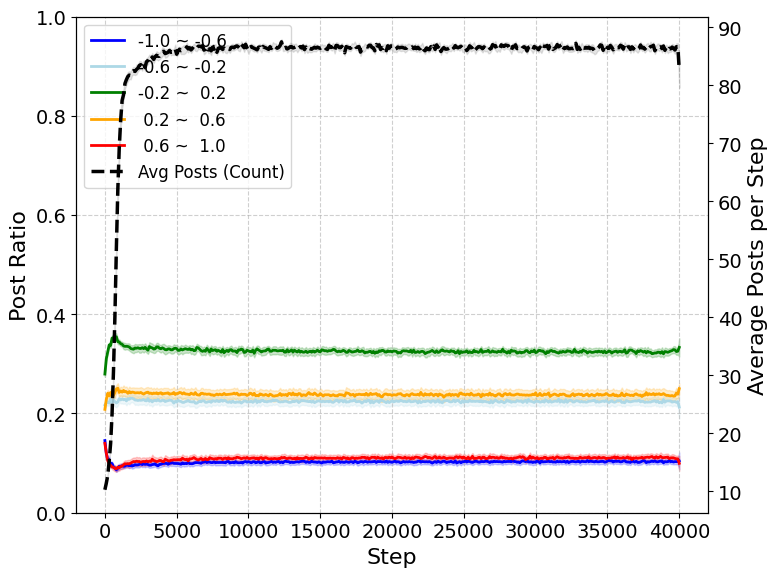

Plot generated.


In [12]:
# ==========================================
# 設定: 文字サイズなどのスタイル定義
# ==========================================
# グラフの文字サイズを全体的に大きく設定（ノートブックのスタイルに合わせる）
plt.rcParams['font.family'] = 'sans-serif'  # お好みのフォントがあれば指定
plt.rcParams['font.size'] = 14              # 基本のフォントサイズ
plt.rcParams['axes.labelsize'] = 16         # 軸ラベルのサイズ
plt.rcParams['axes.titlesize'] = 18         # タイトルのサイズ
plt.rcParams['xtick.labelsize'] = 14        # x軸目盛りのサイズ
plt.rcParams['ytick.labelsize'] = 14        # y軸目盛りのサイズ
plt.rcParams['legend.fontsize'] = 12        # 凡例のサイズ
plt.rcParams['figure.figsize'] = (8, 6)    # 画像サイズを少し大きめに

# ==========================================
# メイン処理
# ==========================================

print(f"Found {len(run_dirs)} seed directories.")

for d in run_dirs:
    seed_name = os.path.basename(d)
    # load_and_process_seed は定義済みの関数と仮定
    df = load_and_process_seed(d, seed_name)
    if df is not None:
        all_dfs.append(df)

if not all_dfs:
    print("No valid data found.")
else:
    # 2. 全データを結合
    full_df = pd.concat(all_dfs, ignore_index=True)
    
    # 3. Stepごとに集計（数値列のみを対象に平均と標準誤差 SE を計算）
    # numeric_only=True を指定して文字列列のエラーを回避
    grouped = full_df.groupby("step")
    df_mean = grouped.mean(numeric_only=True)
    df_se = grouped.sem(numeric_only=True)

    # 結果をCSV保存（オプション）
    df_mean.to_csv(os.path.join(OUTPUT_DIR, "posts_mean_all_seeds.csv"))
    print(f"Aggregated data saved to {OUTPUT_DIR}")

    # ==========================================
    # プロット作成
    # ==========================================
    fig, ax1 = plt.subplots()

    steps = df_mean.index

    # カラーマップの設定
    BIN_COLORS = ["blue", "lightblue", "green", "orange", "red"]

    # --- 左軸: 投稿割合 (bin_0 ~ bin_4) ---
    for i, bin_name in enumerate(BINS):
        if bin_name in df_mean.columns:
            mean_val = df_mean[bin_name]
            se_val = df_se[bin_name]

            current_color = BIN_COLORS[i]
            
            # ラベルを辞書から取得（なければそのままbin名）
            label_text = bin_labels.get(bin_name, bin_name)
            
            # 平均線のプロット
            ax1.plot(steps, mean_val, label=label_text, color=current_color, linewidth=2)
            
            # 誤差範囲(SE)を塗りつぶし (帯をつける処理)
            ax1.fill_between(steps, 
                             mean_val - se_val, 
                             mean_val + se_val, 
                             color=current_color, alpha=0.2) # alphaで透明度調整

    ax1.set_xlabel("Step", fontsize=16)
    ax1.set_ylabel("Post Ratio", fontsize=16)
    ax1.set_ylim(0, 1.0)
    ax1.grid(True, linestyle="--", alpha=0.6)

    # --- 右軸: 投稿数 (sumOfPosts) ---
    # 投稿数データが存在する場合のみ描画
    if "sumOfPosts" in df_mean.columns:
        ax2 = ax1.twinx()
        
        posts_mean = df_mean["sumOfPosts"]
        posts_se = df_se["sumOfPosts"]
        
        # 投稿数は黒の点線で強調
        ax2.plot(steps, posts_mean, label="Avg Posts (Count)", color="black", linestyle="--", linewidth=2.5)
        
        # 投稿数のSE帯
        ax2.fill_between(steps, 
                         posts_mean - posts_se, 
                         posts_mean + posts_se, 
                         color="black", alpha=0.1)
        
        ax2.set_ylabel("Average Posts per Step", fontsize=16)

        # 凡例の結合 (左軸と右軸をまとめる)
        lines1, labels1 = ax1.get_legend_handles_labels()
        lines2, labels2 = ax2.get_legend_handles_labels()
        # 凡例を図の左上に表示
        ax1.legend(lines1 + lines2, labels1 + labels2, bbox_to_anchor=(0, 1), loc='upper left')
    else:
        ax1.legend()

    #plt.title(f"Post Analysis (Window={WINDOW_SIZE if 'WINDOW_SIZE' in locals() else 'N/A'}, Seeds={len(all_dfs)})")
    
    # レイアウト調整（凡例が切れないように）
    plt.tight_layout()
    
    # 画像保存
    plt.savefig(os.path.join(OUTPUT_DIR, "post_analysis_plot.png"))
    plt.show()
    
    print("Plot generated.")

<Figure size 800x600 with 2 Axes>

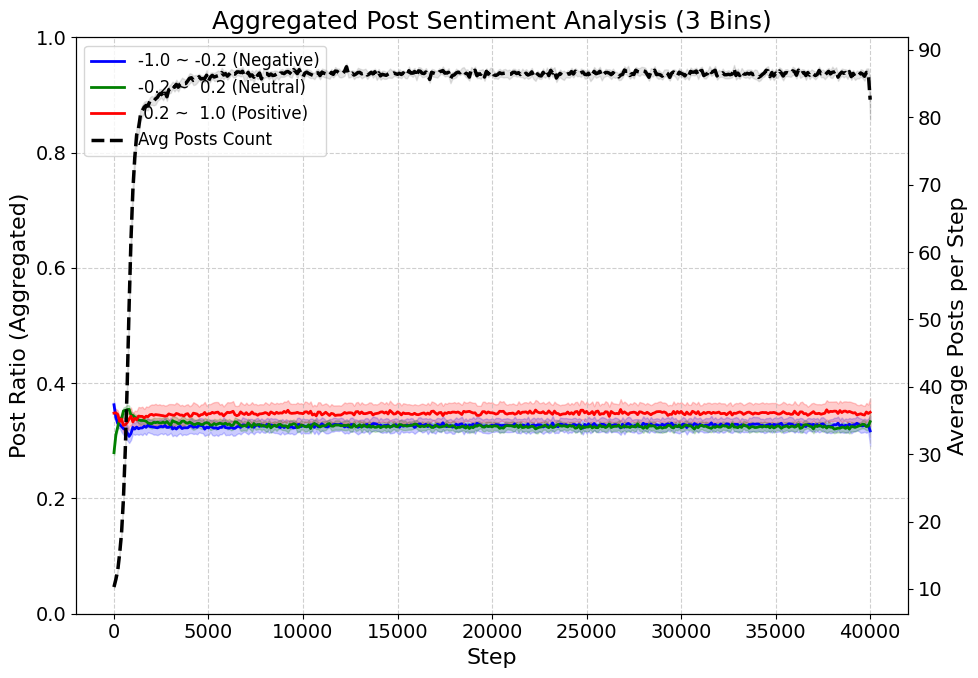

Plot generated successfully (3 bins integrated).


In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# ==========================================
# 3分割統合・プロット用コード
# （Originalコードで all_dfs が作成された直後に実行することを想定）
# ==========================================

# 1. データの結合 (Originalコードですでにロードされた all_dfs を使用)
if 'all_dfs' in locals() and all_dfs:
    full_df = pd.concat(all_dfs, ignore_index=True)
    
    # --- 安全な列の統合処理 (KeyError回避) ---
    # 存在しない列を指定してもエラーにならないよう、チェックしながら足し合わせます
    
    def safe_sum(df, cols):
        """指定された列リストのうち、存在するものを足し合わせる"""
        total = 0.0
        # 少なくとも1つの列が存在するか確認するためのフラグ
        exists = False
        for c in cols:
            if c in df.columns:
                total += df[c]
                exists = True
        
        # どの列も存在しない場合は全行0のSeriesを返す（NaN回避）
        if not exists:
            return pd.Series(0.0, index=df.index)
        return total

    # 3つのカテゴリを作成
    full_df['merged_neg'] = safe_sum(full_df, ['bin_0', 'bin_1']) # -1.0 ~ -0.2
    full_df['merged_neu'] = safe_sum(full_df, ['bin_2'])          # -0.2 ~  0.2
    full_df['merged_pos'] = safe_sum(full_df, ['bin_3', 'bin_4']) #  0.2 ~  1.0

    # 2. Stepごとに集計
    grouped = full_df.groupby("step")
    df_mean = grouped.mean(numeric_only=True)
    df_se = grouped.sem(numeric_only=True)

    # ==========================================
    # プロット作成
    # ==========================================
    fig, ax1 = plt.subplots(figsize=(10, 7)) # サイズ調整

    steps = df_mean.index
    
    # プロット設定
    MERGED_BINS = ['merged_neg', 'merged_neu', 'merged_pos']
    
    bin_labels = {
        "merged_neg": "-1.0 ~ -0.2 (Negative)",
        "merged_neu": "-0.2 ~  0.2 (Neutral)",
        "merged_pos": " 0.2 ~  1.0 (Positive)"
    }
    
    BIN_COLORS = ["blue", "green", "red"]

    # --- 左軸: 投稿割合 (3分割) ---
    for i, bin_name in enumerate(MERGED_BINS):
        # 列が計算結果に含まれているか確認（safe_sumで作っているので基本はあるはずですが念のため）
        if bin_name in df_mean.columns:
            mean_val = df_mean[bin_name]
            se_val = df_se[bin_name]

            current_color = BIN_COLORS[i]
            label_text = bin_labels.get(bin_name, bin_name)
            
            # 平均線
            ax1.plot(steps, mean_val, label=label_text, color=current_color, linewidth=2)
            
            # SE帯（エラーバーの代わり）
            ax1.fill_between(steps, 
                             mean_val - se_val, 
                             mean_val + se_val, 
                             color=current_color, alpha=0.2)

    ax1.set_xlabel("Step", fontsize=16)
    ax1.set_ylabel("Post Ratio (Aggregated)", fontsize=16)
    ax1.set_ylim(0, 1.0) # 割合なので0-1固定
    ax1.grid(True, linestyle="--", alpha=0.6)
    ax1.set_title("Aggregated Post Sentiment Analysis (3 Bins)", fontsize=18)

    # --- 右軸: 投稿数 (sumOfPosts) ---
    if "sumOfPosts" in df_mean.columns:
        ax2 = ax1.twinx()
        
        posts_mean = df_mean["sumOfPosts"]
        posts_se = df_se["sumOfPosts"]
        
        ax2.plot(steps, posts_mean, label="Avg Posts Count", color="black", linestyle="--", linewidth=2.5)
        ax2.fill_between(steps, 
                         posts_mean - posts_se, 
                         posts_mean + posts_se, 
                         color="black", alpha=0.1)
        
        ax2.set_ylabel("Average Posts per Step", fontsize=16)

        # 凡例の結合
        lines1, labels1 = ax1.get_legend_handles_labels()
        lines2, labels2 = ax2.get_legend_handles_labels()
        ax1.legend(lines1 + lines2, labels1 + labels2, bbox_to_anchor=(0, 1), loc='upper left')
    else:
        ax1.legend(loc='upper left')

    plt.tight_layout()
    
    # 保存先ディレクトリ変数がなければカレントディレクトリへ
    save_dir = OUTPUT_DIR if 'OUTPUT_DIR' in locals() else '.'
    plt.savefig(os.path.join(save_dir, "post_analysis_3bins_fixed.png"))
    plt.show()
    
    print("Plot generated successfully (3 bins integrated).")

else:
    print("Error: 'all_dfs' is not defined. Please run the data loading code first.")